# Agribusiness Predictive Modelling Pipeline
## Executed on the real World Bank Commodity Price Data (Pink Sheet)

**Worked benchmark:** monthly wheat price (US HRW, Gulf Ports, USD/metric ton), 2000–2026  
**Extended check:** rice, maize, soybeans and cotton at a 3-month horizon  
**Evaluation:** expanding-window rolling-origin backtest over 60 folds, four horizons (1, 3, 6, 12 months)  
**Model ladder:** Random Walk → Seasonal Naïve → ETS → SARIMAX → Gradient-Boosted Trees → inverse-error Ensemble

---

### What makes this notebook real

| Item | Value |
|---|---|
| Dataset | World Bank *Commodity Markets Outlook* historical monthly prices (the Pink Sheet) |
| Original workbook | `CMO-Historical-Data-Monthly.xlsx`, sheet `Monthly Prices` |
| Coverage | Monthly observations from January 1960 to the latest published month (802 rows in the prepared extract) |
| Modelling window | January 2000 to the latest published month |
| Data licence | World Bank open data; cite the World Bank Commodity Markets Outlook |
| Execution | Runs top-to-bottom in Google Colab or a local Jupyter kernel; no manual edits |

### Scope note

The Week 4 Word report's performance matrix is a **design target / illustrative specification**.
This notebook is the **executed evidence** on real prices: every number below is produced by the
code in this file during execution. Where a rung fails the promotion gate, it is reported as a
failure rather than removed. The two will not necessarily agree, and the executed table is the
authoritative empirical result.

### Protocol commitments

1. **No shuffling.** Training data always precedes the forecast origin.
2. **Direct multi-horizon targets.** For horizon *h*, the model learns `y[t+h]` from information
   available at `t`; it never sees `y[t+1] … y[t+h-1]` at prediction time.
3. **No global decomposition leakage.** STL is used for diagnosis only; its two-sided trend and
   seasonal components are **not** fed to the models. Calendar effects enter through sine/cosine terms.
4. **Causal ensemble weights.** L5 weights at fold *k* use squared errors from folds `< k` only.
5. **Exogenous cost drivers projected flat.** DAP and urea at future dates are held at their last
   observed value, which is the information a forecaster actually has at the origin.

## 0. Environment setup

Google Colab already ships pandas, NumPy, scikit-learn, statsmodels, matplotlib and openpyxl.
The cell below only reports versions; it installs nothing, so it cannot break a working kernel.

In [1]:
%matplotlib inline

import os
import re
import json
import platform
import warnings
import urllib.request
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

_style = "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
plt.style.use(_style)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#B9C6BC",
    "axes.linewidth": 1.1,
    "legend.frameon": True,
})

print(f"Environment : {'Google Colab' if IN_COLAB else 'local Jupyter / IPython'}")
print(f"Python      : {platform.python_version()}")
print(f"pandas      : {pd.__version__}")
print(f"NumPy       : {np.__version__}")
import sklearn, statsmodels, matplotlib
print(f"scikit-learn: {sklearn.__version__}")
print(f"statsmodels : {statsmodels.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")

Environment : local Jupyter / IPython
Python      : 3.14.2
pandas      : 3.0.0
NumPy       : 2.4.2
scikit-learn: 1.9.1
statsmodels : 0.15.0
matplotlib  : 3.11.2


## 1. Load the real World Bank dataset

The loader is deliberately defensive, because a notebook that only works on the author's laptop
is not reproducible:

1. Look for the prepared CSV in the usual repository locations.
2. If it is absent, download the **official World Bank workbook** and parse the `Monthly Prices`
   sheet directly (header names are matched, not hard-coded column numbers).
3. If the download is blocked, offer a Google Colab upload dialog.

The prepared CSV is a convenience extract, not a substitute: the parser below rebuilds it from the
World Bank workbook whenever the file is missing.

In [2]:
DATA_FILENAME = "world_bank_commodity_prices_1960_2026.csv"
# The World Bank rotates the document hash each month. Try the current edition first,
# then a long-lived mirror, so the notebook keeps working after the next data release.
WB_XLSX_URLS = [
    "https://thedocs.worldbank.org/en/doc/"
    "74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/CMO-Historical-Data-Monthly.xlsx",
    "https://thedocs.worldbank.org/en/doc/"
    "5d903e848db1d1b83e0ec8f744e55570-0350012021/related/CMO-Historical-Data-Monthly.xlsx",
]

# Prepared column -> header text in the World Bank "Monthly Prices" sheet.
REQUIRED = {
    "Wheat_HRW_USD_MT":      "Wheat, US HRW",
    "Rice_Thai_USD_MT":      "Rice, Thai 5%",
    "Maize_USD_MT":          "Maize",
    "Soybeans_USD_MT":       "Soybeans",
    "Cotton_AIndex_USD_MT":  "Cotton, A Index",
    "DAP_Fertilizer_USD_MT": "DAP",
    "Urea_Fertilizer_USD_MT": "Urea",
}
UNITS = {
    "Wheat_HRW_USD_MT": "USD / metric ton",
    "Rice_Thai_USD_MT": "USD / metric ton",
    "Maize_USD_MT": "USD / metric ton",
    "Soybeans_USD_MT": "USD / metric ton",
    "Cotton_AIndex_USD_MT": "USD / metric ton (converted from USD/kg)",
    "DAP_Fertilizer_USD_MT": "USD / metric ton",
    "Urea_Fertilizer_USD_MT": "USD / metric ton",
}


def find_local_csv(filename):
    here = Path.cwd()
    candidates = [
        here / filename,
        here / "data" / filename,
        here.parent / "data" / filename,
        here.parent.parent / "week4" / "data" / filename,
        here.parent.parent / "data" / filename,
    ]
    for path in candidates:
        if path.exists():
            return path.resolve()
    return None


def parse_pink_sheet(xlsx_path):
    # Parse the World Bank Monthly Prices sheet into the prepared schema.
    raw = pd.read_excel(xlsx_path, sheet_name="Monthly Prices", header=None)

    header_row = None
    for i in range(min(15, len(raw))):
        values = [str(v).strip() for v in raw.iloc[i].tolist()]
        if "Wheat, US HRW" in values and "DAP" in values:
            header_row = i
            break
    if header_row is None:
        raise ValueError("Could not locate the header row in the Monthly Prices sheet.")

    header = [str(v).strip() for v in raw.iloc[header_row].tolist()]

    def column_for(name):
        exact = [j for j, h in enumerate(header) if h == name]
        if exact:
            return exact[0]
        prefix = [j for j, h in enumerate(header) if h.startswith(name)]
        if prefix:
            return prefix[0]
        raise KeyError(f"Column {name!r} not found in the World Bank sheet.")

    col_map = {target: column_for(source) for target, source in REQUIRED.items()}
    records = []
    for i in range(header_row + 2, len(raw)):
        code = raw.iat[i, 0]
        if not isinstance(code, str):
            continue
        code = code.strip()
        if not re.fullmatch(r"\d{4}M\d{2}", code):
            continue
        year, month = int(code[:4]), int(code[5:])
        if not 1 <= month <= 12:
            continue
        row = {"Date_Code": code, "Date": f"{year:04d}-{month:02d}-01", "Year": year, "Month": month}
        for target, j in col_map.items():
            value = raw.iat[i, j]
            try:
                value = float(value) if pd.notna(value) else np.nan
            except (TypeError, ValueError):
                value = np.nan
            # The Pink Sheet quotes cotton in USD/kg; the prepared panel is USD/metric ton.
            if target == "Cotton_AIndex_USD_MT" and np.isfinite(value):
                value *= 1000.0
            row[target] = value
        records.append(row)

    out = pd.DataFrame(records).sort_values("Date").reset_index(drop=True)
    if out.empty:
        raise ValueError("The World Bank sheet produced zero monthly rows.")
    return out


csv_path = find_local_csv(DATA_FILENAME)

if csv_path is not None:
    df_raw = pd.read_csv(csv_path)
    data_source = f"local CSV: {csv_path}"
else:
    xlsx_path = Path.cwd() / "CMO-Historical-Data-Monthly.xlsx"
    df_raw = None
    download_error = None
    print("Prepared CSV not found. Trying the official World Bank workbook...")
    for url in WB_XLSX_URLS:
        try:
            request = urllib.request.Request(
                url,
                headers={"User-Agent": "Mozilla/5.0 (compatible; Agribusiness-Notebook/1.0)"},
            )
            with urllib.request.urlopen(request, timeout=120) as response, open(xlsx_path, "wb") as handle:
                handle.write(response.read())
            df_raw = parse_pink_sheet(xlsx_path)
            prepared = Path.cwd() / DATA_FILENAME
            df_raw.to_csv(prepared, index=False)
            data_source = f"World Bank Pink Sheet (live download, saved to {prepared})"
            break
        except Exception as exc:
            download_error = exc
            print(f"  attempt failed: {exc}")

    if df_raw is None:
        if IN_COLAB:
            print("Download failed; opening the Colab upload dialog.")
            print(f"Reason: {download_error}")
            from google.colab import files
            uploaded = files.upload()
            if not uploaded:
                raise FileNotFoundError("No file uploaded.")
            uploaded_name = next(iter(uploaded))
            df_raw = pd.read_csv(uploaded_name)
            data_source = f"Colab upload: {uploaded_name}"
        else:
            raise FileNotFoundError(
                "Could not find the prepared CSV and could not download the World Bank workbook. "
                f"Place {DATA_FILENAME} in week4/data/ or run this notebook in Colab.\n"
                f"Download error: {download_error}"
            )

df_raw["Date"] = pd.to_datetime(df_raw["Date"])
df_raw = df_raw.sort_values("Date").drop_duplicates("Date").reset_index(drop=True)

expected_months = pd.date_range(df_raw["Date"].min(), df_raw["Date"].max(), freq="MS")
missing_months = expected_months.difference(pd.DatetimeIndex(df_raw["Date"]))

print(f"Data source : {data_source}")
print(f"Shape       : {df_raw.shape[0]:,} monthly rows x {df_raw.shape[1]} columns")
print(f"Coverage    : {df_raw['Date'].min():%Y-%m} to {df_raw['Date'].max():%Y-%m}")
print(f"Missing months in the date index: {len(missing_months)}")
assert len(missing_months) == 0, "The monthly series has gaps; inspect before modelling."
assert df_raw["Date"].is_monotonic_increasing
df_raw.tail(3)

Data source : local CSV: C:\Users\samru\Desktop\yuvaintern\weeks\week4\data\world_bank_commodity_prices_1960_2026.csv
Shape       : 802 monthly rows x 11 columns
Coverage    : 1960-01 to 2026-10
Missing months in the date index: 0


,Date_Code,Date,Year,Month,Wheat_HRW_USD_MT,Rice_Thai_USD_MT,Maize_USD_MT,Soybeans_USD_MT,Cotton_AIndex_USD_MT,DAP_Fertilizer_USD_MT,Urea_Fertilizer_USD_MT
799,2026M08,2026-08-01,2026,8,330.000,471.000,224.000,482.000,"2,110.000",793.500,390.000
800,2026M09,2026-09-01,2026,9,347.000,482.000,239.600,524.000,"2,100.000",800.600,407.500
801,2026M10,2026-10-01,2026,10,317.000,489.000,226.500,515.000,"2,000.000",803.100,420.000


### 1.1 Data audit and data dictionary

Before any modelling, confirm that the columns are present, the units are consistent, and the
missing values are understood. The DAP series begins later than wheat, which is why the modelling
window starts in 2000 and why the design matrix drops rows whose fertilizer lags are missing.

In [3]:
modern = df_raw.loc[df_raw["Date"] >= "2000-01-01"].copy().reset_index(drop=True)
assert modern[list(REQUIRED)].isna().sum().sum() == 0, "Unexpected missing values in the modern window."

audit = pd.DataFrame({
    "column": list(REQUIRED),
    "unit": [UNITS[c] for c in REQUIRED],
    "non_null": [int(df_raw[c].notna().sum()) for c in REQUIRED],
    "missing": [int(df_raw[c].isna().sum()) for c in REQUIRED],
    "minimum": [float(df_raw[c].min()) for c in REQUIRED],
    "maximum": [float(df_raw[c].max()) for c in REQUIRED],
    "latest": [float(df_raw[c].iloc[-1]) for c in REQUIRED],
})
display(audit)

print("\nDescriptive statistics, modern window (2000-01 to 2026-09):")
display(modern[list(REQUIRED)].describe().T)

print("\nSource workbook column names and units (Pink Sheet):")
source_units = pd.DataFrame({
    "prepared_column": list(REQUIRED),
    "world_bank_header": [REQUIRED[c] for c in REQUIRED],
    "unit": [UNITS[c] for c in REQUIRED],
})
display(source_units)

,column,unit,non_null,missing,minimum,maximum,latest
0,Wheat_HRW_USD_MT,USD / metric ton,802,0,52.200,522.300,317.000
1,Rice_Thai_USD_MT,USD / metric ton,802,0,95.700,907.000,489.000
2,Maize_USD_MT,USD / metric ton,802,0,38.000,348.200,226.500
3,Soybeans_USD_MT,USD / metric ton,802,0,88.000,737.000,515.000
4,Cotton_AIndex_USD_MT,USD / metric ton (converted from USD/kg),802,0,600.000,"5,060.000","2,000.000"
5,DAP_Fertilizer_USD_MT,USD / metric ton,718,84,54.000,"1,075.800",803.100
6,Urea_Fertilizer_USD_MT,USD / metric ton,802,0,16.000,925.000,420.000



Descriptive statistics, modern window (2000-01 to 2026-09):


,count,mean,std,min,25%,50%,75%,max
Wheat_HRW_USD_MT,322.000,235.701,82.306,105.100,168.650,219.750,290.675,522.300
Rice_Thai_USD_MT,322.000,409.221,137.210,163.800,310.025,419.500,508.500,907.000
Maize_USD_MT,322.000,182.002,67.806,75.300,135.675,167.350,220.700,348.200
Soybeans_USD_MT,322.000,416.292,132.303,184.000,322.750,407.500,518.250,737.000
Cotton_AIndex_USD_MT,322.000,"1,755.994",583.313,820.000,"1,342.500","1,700.000","1,997.500","5,060.000"
DAP_Fertilizer_USD_MT,322.000,408.645,203.512,133.100,241.675,390.650,535.400,"1,075.800"
Urea_Fertilizer_USD_MT,322.000,298.388,159.691,77.400,209.400,263.800,365.550,925.000



Source workbook column names and units (Pink Sheet):


,prepared_column,world_bank_header,unit
0,Wheat_HRW_USD_MT,"Wheat, US HRW",USD / metric ton
1,Rice_Thai_USD_MT,"Rice, Thai 5%",USD / metric ton
2,Maize_USD_MT,Maize,USD / metric ton
3,Soybeans_USD_MT,Soybeans,USD / metric ton
4,Cotton_AIndex_USD_MT,"Cotton, A Index",USD / metric ton (converted from USD/kg)
5,DAP_Fertilizer_USD_MT,DAP,USD / metric ton
6,Urea_Fertilizer_USD_MT,Urea,USD / metric ton


## 2. Exploratory view of the real price history

The three panels show the shocks the models must survive: the 2007–08 food crisis, the 2011–12
drought, the 2021–22 energy and freight shock, and the 2022–23 fertilizer spike. A model that only
learns a smooth trend will fail on these regime changes, which is exactly why the random walk is a
serious benchmark rather than a formality.

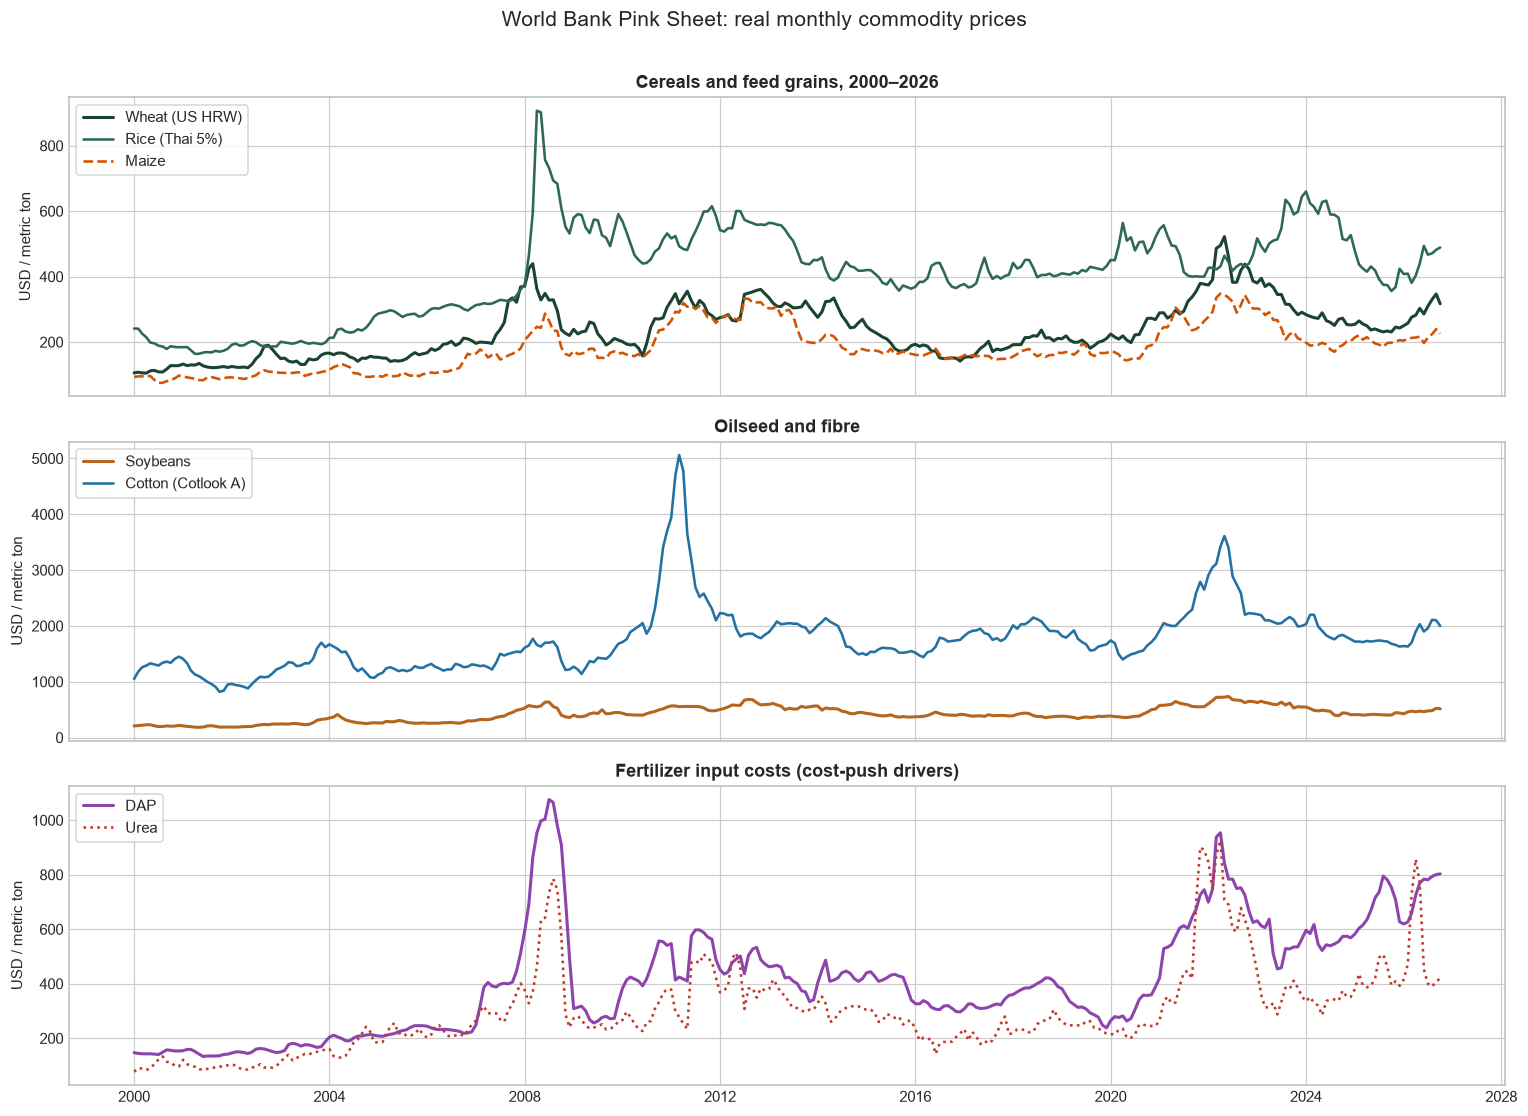

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(modern["Date"], modern["Wheat_HRW_USD_MT"], color="#1B4332", lw=2, label="Wheat (US HRW)")
axes[0].plot(modern["Date"], modern["Rice_Thai_USD_MT"], color="#2D6A4F", lw=1.7, label="Rice (Thai 5%)")
axes[0].plot(modern["Date"], modern["Maize_USD_MT"], color="#D35400", lw=1.7, ls="--", label="Maize")
axes[0].set_ylabel("USD / metric ton")
axes[0].set_title("Cereals and feed grains, 2000–2026")
axes[0].legend(loc="upper left")

axes[1].plot(modern["Date"], modern["Soybeans_USD_MT"], color="#B5651D", lw=2, label="Soybeans")
axes[1].plot(modern["Date"], modern["Cotton_AIndex_USD_MT"], color="#2471A3", lw=1.7, label="Cotton (Cotlook A)")
axes[1].set_ylabel("USD / metric ton")
axes[1].set_title("Oilseed and fibre")
axes[1].legend(loc="upper left")

axes[2].plot(modern["Date"], modern["DAP_Fertilizer_USD_MT"], color="#8E44AD", lw=2, label="DAP")
axes[2].plot(modern["Date"], modern["Urea_Fertilizer_USD_MT"], color="#C0392B", lw=1.7, ls=":", label="Urea")
axes[2].set_ylabel("USD / metric ton")
axes[2].set_title("Fertilizer input costs (cost-push drivers)")
axes[2].legend(loc="upper left")
axes[2].xaxis.set_major_locator(mdates.YearLocator(4))

fig.suptitle("World Bank Pink Sheet: real monthly commodity prices", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 2.1 STL decomposition — diagnostic only

STL separates a series into trend, seasonal and residual components. It is useful for reading the
data, but a **centred** decomposition uses observations on both sides of each month. Feeding those
components into a model would leak future information. The models below therefore use only lagged
and rolling features computed from the past, plus calendar sine/cosine terms.

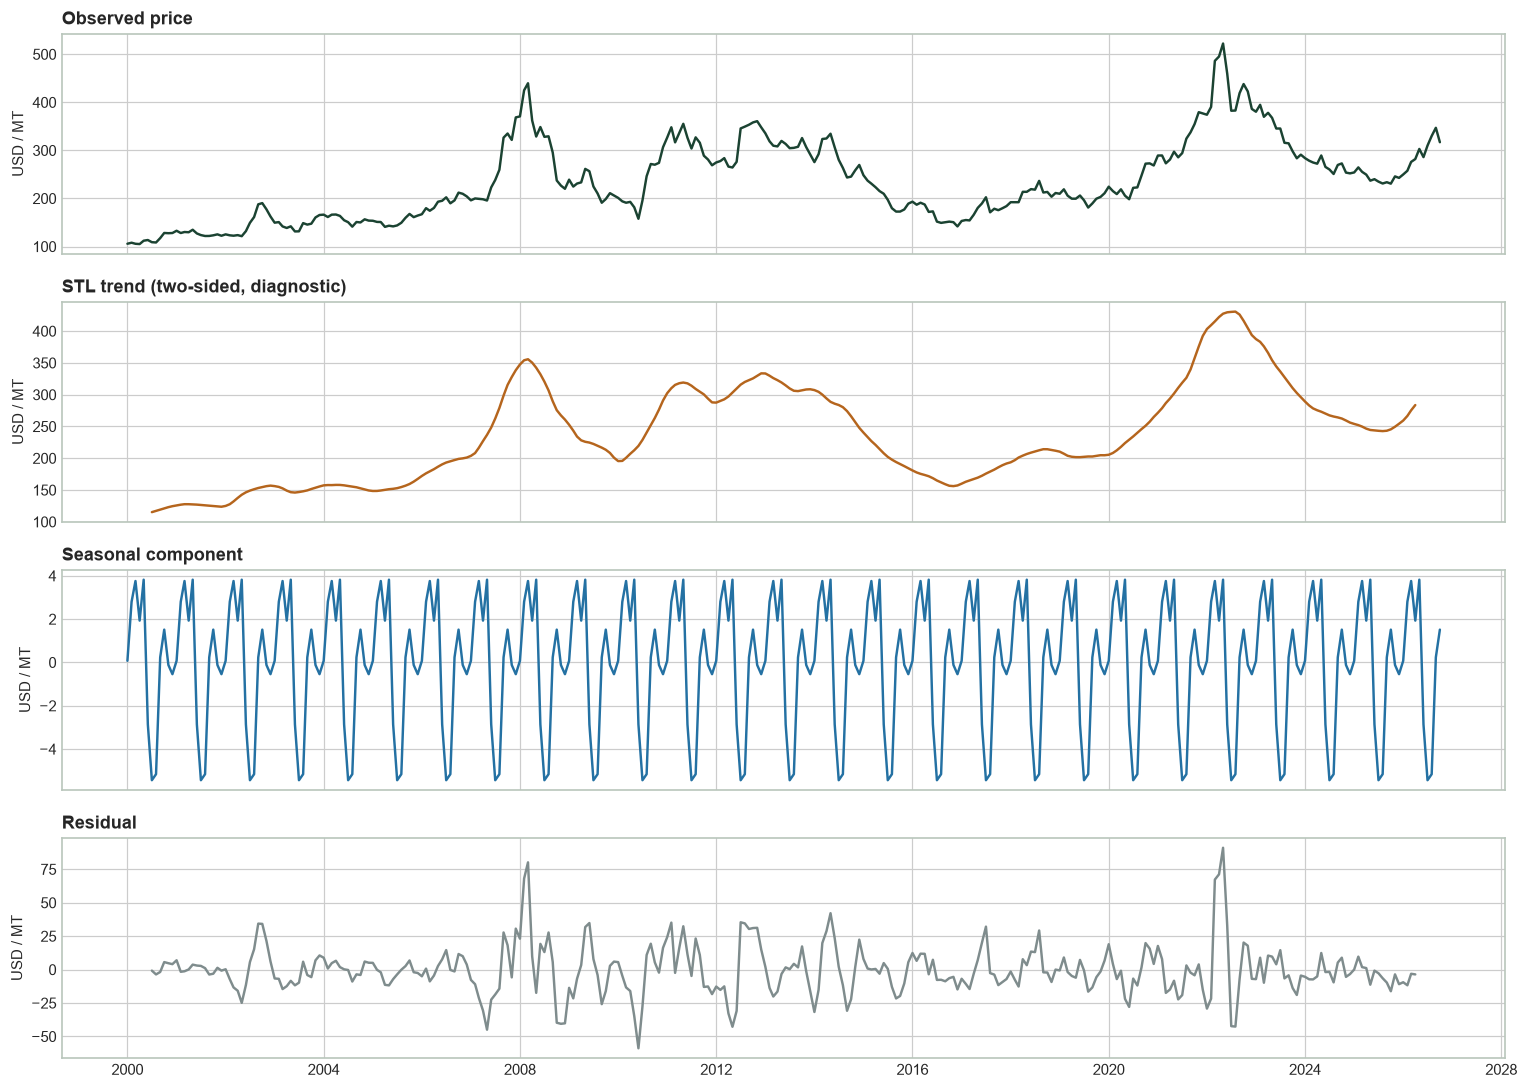

Seasonal strength (0–1): 0.026
Trend strength    (0–1): 0.949
These components are NOT used as predictors; only past-only features enter the models.


In [5]:
wheat_series = modern.set_index("Date")["Wheat_HRW_USD_MT"].asfreq("MS")
stl = seasonal_decompose(wheat_series, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
parts = [
    (stl.observed, "Observed price", "#1B4332"),
    (stl.trend, "STL trend (two-sided, diagnostic)", "#B5651D"),
    (stl.seasonal, "Seasonal component", "#2471A3"),
    (stl.resid, "Residual", "#7F8C8D"),
]
for ax, (series, title, colour) in zip(axes, parts):
    ax.plot(series.index, series.values, color=colour, lw=1.6)
    ax.set_title(title, loc="left")
    ax.set_ylabel("USD / MT")

plt.tight_layout()
plt.show()

seasonal_strength = max(0.0, 1 - np.nanvar(stl.resid) / np.nanvar(stl.seasonal + stl.resid))
trend_strength = max(0.0, 1 - np.nanvar(stl.resid) / np.nanvar(stl.trend + stl.resid))
print(f"Seasonal strength (0–1): {seasonal_strength:.3f}")
print(f"Trend strength    (0–1): {trend_strength:.3f}")
print("These components are NOT used as predictors; only past-only features enter the models.")

## 3. Causal feature engineering

Every feature at row `t` is a function of observations dated `t` or earlier:

| Family | Features | Why it is in the design |
|---|---|---|
| Price memory | lags 1, 2, 3, 6, 12; current level | Persistence and distributed-lag transmission |
| Momentum | 1-, 3-, 12-month returns; 3m/12m mean ratio | Regime direction |
| Volatility | 3-, 6-, 12-month rolling standard deviation | Turbulence and uncertainty |
| Cost push | DAP and urea at lags 0, 1, 3, 6; fertilizer/price ratios | Input-cost transmission |
| Mean reversion | 12-month drawdown; year-on-year ratio | Overshoot and correction |
| Calendar | month sine and cosine | Harvest-cycle seasonality without leakage |

The target for horizon *h* is the **log return** `log(y[t+h] / y[t])` for the tree model, so the
tree predicts a change rather than extrapolating a price level it has never seen. ETS and SARIMAX
forecast the level directly, as they are designed to do.

In [6]:
TARGET = "Wheat_HRW_USD_MT"
EXOG = ["DAP_Fertilizer_USD_MT", "Urea_Fertilizer_USD_MT"]
LAGS = [1, 2, 3, 6, 12]


def build_design(frame, target=TARGET, exog=EXOG):
    # Build a past-only design matrix for one commodity price series.
    data = frame[["Date", target, *exog]].copy().rename(columns={target: "y"})
    data = data.sort_values("Date").reset_index(drop=True)

    for lag in LAGS:
        data[f"y_lag{lag}"] = data["y"].shift(lag)
    for column in exog:
        short = "dap" if column.startswith("DAP") else "urea"
        for lag in [0, 1, 3, 6]:
            data[f"{short}_lag{lag}"] = data[column].shift(lag)

    for window in [3, 6, 12]:
        data[f"roll_mean_{window}"] = data["y"].shift(1).rolling(window).mean()
        data[f"roll_std_{window}"] = data["y"].shift(1).rolling(window).std()

    data["ret_1m"] = data["y"].pct_change(1, fill_method=None)
    data["ret_3m"] = data["y"].pct_change(3, fill_method=None)
    data["ret_12m"] = data["y"].pct_change(12, fill_method=None)
    data["mom_3_12"] = data["roll_mean_3"] / data["roll_mean_12"] - 1
    data["yoy_ratio"] = data["y"] / data["y_lag12"] - 1
    data["dap_to_price"] = data["dap_lag0"] / data["y"]
    data["urea_to_price"] = data["urea_lag0"] / data["y"]
    data["drawdown_12"] = data["y"] / data["y"].rolling(12).max() - 1

    month = data["Date"].dt.month
    data["month_sin"] = np.sin(2 * np.pi * month / 12)
    data["month_cos"] = np.cos(2 * np.pi * month / 12)

    data = data.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    features = [c for c in data.columns if c not in ("Date", "y")]
    return data, features


design, FEATURES = build_design(modern)
print(f"Design matrix: {design.shape[0]} usable months x {design.shape[1]} columns")
print(f"Modelling window: {design['Date'].min():%Y-%m} to {design['Date'].max():%Y-%m}")
print(f"Predictors ({len(FEATURES)}):")
for i in range(0, len(FEATURES), 4):
    print("  " + ", ".join(FEATURES[i:i + 4]))

display(design[["Date", "y", "y_lag1", "roll_std_3", "dap_to_price", "month_sin"]].head())

Design matrix: 310 usable months x 33 columns
Modelling window: 2001-01 to 2026-10
Predictors (31):
  DAP_Fertilizer_USD_MT, Urea_Fertilizer_USD_MT, y_lag1, y_lag2
  y_lag3, y_lag6, y_lag12, dap_lag0
  dap_lag1, dap_lag3, dap_lag6, urea_lag0
  urea_lag1, urea_lag3, urea_lag6, roll_mean_3
  roll_std_3, roll_mean_6, roll_std_6, roll_mean_12
  roll_std_12, ret_1m, ret_3m, ret_12m
  mom_3_12, yoy_ratio, dap_to_price, urea_to_price
  drawdown_12, month_sin, month_cos


,Date,y,y_lag1,roll_std_3,dap_to_price,month_sin
0,2001-01-01,132.800,128.100,0.265,1.163,0.500
1,2001-02-01,128.100,132.800,2.836,1.241,0.866
2,2001-03-01,130.200,128.100,2.714,1.222,1.000
3,2001-04-01,129.700,130.200,2.354,1.167,0.866
4,2001-05-01,134.900,129.700,1.097,1.053,0.500


## 4. Rolling-origin protocol

The backtest uses an **expanding window**. At each origin `t`:

- training uses months `0 … t`;
- the forecast is for `y[t+h]`;
- the origin then advances by three months.

With a 120-month initial window and a 12-month maximum horizon, the notebook builds an expanding
sequence of folds (60 at the current vintage). Origins are placed automatically so that no horizon
runs past the final observation; at this vintage the last 12-month target is September 2026 and
October 2026 remains held back. Nothing after a target date enters its forecast. The executed counts are printed by the next cell, so the notebook remains
correct when the World Bank publishes a new month.

Usable months      : 310
Rolling origins    : 60
Initial train size : 120 months
Step size          : 3 months
First origin       : 2010-12
Last origin        : 2025-09
Last target (h=12) : 2026-09


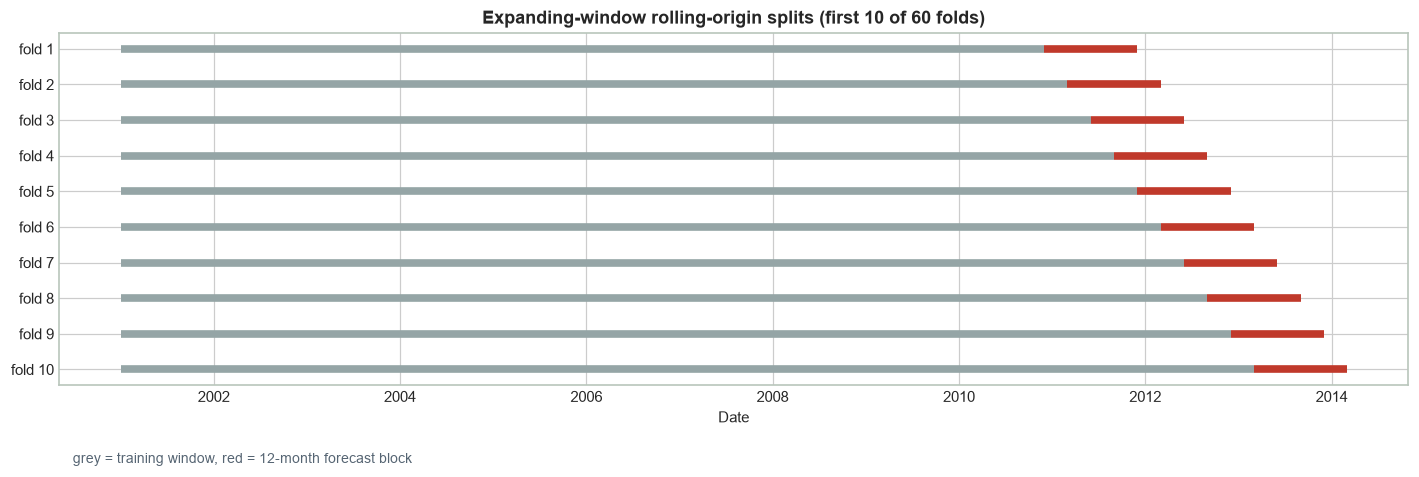

In [7]:
HORIZONS = [1, 3, 6, 12]
MAX_H = max(HORIZONS)
MIN_TRAIN = 120
STEP = 3


def rolling_origins(n_rows, min_train=MIN_TRAIN, max_h=MAX_H, step=STEP):
    # Return indices of forecast origins; origin o means train 0..o and target o+h.
    return list(range(min_train - 1, n_rows - max_h, step))


ORIGINS = rolling_origins(len(design))
print(f"Usable months      : {len(design)}")
print(f"Rolling origins    : {len(ORIGINS)}")
print(f"Initial train size : {MIN_TRAIN} months")
print(f"Step size          : {STEP} months")
print(f"First origin       : {design.loc[ORIGINS[0], 'Date']:%Y-%m}")
print(f"Last origin        : {design.loc[ORIGINS[-1], 'Date']:%Y-%m}")
print(f"Last target (h=12) : {design.loc[ORIGINS[-1] + MAX_H, 'Date']:%Y-%m}")

fig, ax = plt.subplots(figsize=(13, 4.5))
for i, origin in enumerate(ORIGINS[:10]):
    ax.plot([design.loc[0, "Date"], design.loc[origin, "Date"]], [i, i], color="#95A5A6", lw=5, solid_capstyle="butt")
    ax.plot([design.loc[origin, "Date"], design.loc[min(origin + MAX_H, len(design) - 1), "Date"]], [i, i], color="#C0392B", lw=5, solid_capstyle="butt")
ax.invert_yaxis()
ax.set_yticks(range(10))
ax.set_yticklabels([f"fold {i+1}" for i in range(10)])
ax.set_title("Expanding-window rolling-origin splits (first 10 of 60 folds)")
ax.set_xlabel("Date")
ax.text(0.01, -0.22, "grey = training window, red = 12-month forecast block",
        transform=ax.transAxes, fontsize=9, color="#566573")
plt.tight_layout()
plt.show()

## 5. The six-rung model ladder

| Rung | Model | Implementation detail |
|---|---|---|
| L0 | Random walk | `ŷ[t+h] = y[t]` |
| L1 | Seasonal naïve | `ŷ[t+h] = y[t+h-12]` |
| L2 | ETS | additive trend and seasonality, estimated by statsmodels |
| L3 | SARIMAX | `(1,1,1)(1,0,0)[12]`, with DAP and urea; future exog held flat |
| L4 | GBDT | histogram gradient boosting on the log return, one direct model per horizon |
| L5 | Ensemble | inverse-MSE blend of L2–L4, weights learned from **earlier folds only** |

### Metrics

- **MAE / RMSE / sMAPE** — absolute accuracy.
- **MASE** — MAE divided by the in-sample one-step naïve MAE of the first 120 months. This is the
  standard Hyndman definition; for multi-step forecasts it is normally above 1, so it is reported
  for comparability rather than used as the gate.
- **MASE vs RW** — MAE divided by the random-walk MAE at the same horizon. The random walk therefore
  scores exactly 1.00. This is the gate the framework describes.
- **MASE vs SN** — MAE divided by the seasonal-naïve MAE at the same horizon.
- **Directional accuracy** — share of folds where the predicted change from the origin has the same
  sign as the realised change. It is undefined for the random walk, whose predicted change is zero,
  so that cell is left blank.
- **Promotion gate** — `MASE vs RW < 1` **and** `MASE vs SN < 1`.

In [8]:
MODEL_LABELS = {
    "L0": "L0 Random Walk",
    "L1": "L1 Seasonal Naive",
    "L2": "L2 ETS",
    "L3": "L3 SARIMAX",
    "L4": "L4 GBDT (direct)",
    "L5": "L5 Ensemble",
}
BASE_MODELS = ["L0", "L1"]
CANDIDATES = ["L2", "L3", "L4"]  # ensemble members; L5 is the blend itself


def score(y_true, y_pred, origin, scale, rw_mae, sn_mae):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    origin = np.asarray(origin, float)
    error = y_true - y_pred
    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(np.mean(error ** 2)))
    smape = float(100 * np.mean(2 * np.abs(error) / (np.abs(y_true) + np.abs(y_pred) + 1e-9)))
    if np.allclose(y_pred, origin):
        directional = np.nan  # zero predicted change has no sign
    else:
        directional = float(100 * np.mean(np.sign(y_true - origin) == np.sign(y_pred - origin)))
    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape,
        "DirAcc": directional,
        "MASE": mae / scale,
        "MASE_vs_RW": mae / rw_mae,
        "MASE_vs_SN": mae / sn_mae,
    }


def run_ladder(data, features, horizons=HORIZONS, min_train=MIN_TRAIN, step=STEP):
    # Execute L0-L5 on one commodity with an expanding-window backtest.
    y = data["y"].to_numpy(float)
    dates = data["Date"].to_numpy()
    X = data[features].to_numpy(float)
    exog = data[EXOG].to_numpy(float)
    n = len(data)
    max_h = max(horizons)
    origins = rolling_origins(n, min_train=min_train, max_h=max_h, step=step)

    predictions = {h: {k: [] for k in MODEL_LABELS} for h in horizons}
    truth = {h: [] for h in horizons}
    origin_level = {h: [] for h in horizons}
    target_dates = {h: [] for h in horizons}
    origin_dates = {h: [] for h in horizons}

    # Squared errors used only to set next-fold ensemble weights.
    running_sq = {h: {k: [] for k in CANDIDATES} for h in horizons}
    failures = {"L2": 0, "L3": 0, "L4": 0}

    for fold, origin in enumerate(origins):
        for h in horizons:
            truth[h].append(y[origin + h])
            origin_level[h].append(y[origin])
            target_dates[h].append(dates[origin + h])
            origin_dates[h].append(dates[origin])

        # ---- L0 random walk and L1 seasonal naive
        for h in horizons:
            predictions[h]["L0"].append(y[origin])
            predictions[h]["L1"].append(y[origin + h - 12])

        # ---- L2 ETS: fit once, forecast the longest horizon, slice each h
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                ets = ExponentialSmoothing(
                    y[: origin + 1],
                    trend="add",
                    seasonal="add",
                    seasonal_periods=12,
                    initialization_method="estimated",
                ).fit()
                ets_path = np.asarray(ets.forecast(max_h), float)
        except Exception:
            failures["L2"] += 1
            ets_path = np.repeat(y[origin], max_h)

        # ---- L3 SARIMAX: future exog projected flat at the last observed values
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                sarimax = SARIMAX(
                    y[: origin + 1],
                    exog=exog[: origin + 1],
                    order=(1, 1, 1),
                    seasonal_order=(1, 0, 0, 12),
                    enforce_stationarity=False,
                    enforce_invertibility=False,
                ).fit(disp=False)
                future_exog = np.repeat(exog[origin][None, :], max_h, axis=0)
                sarimax_path = np.asarray(sarimax.forecast(steps=max_h, exog=future_exog), float)
        except Exception:
            failures["L3"] += 1
            sarimax_path = ets_path.copy()

        # ---- L4 direct GBDT per horizon, predicting the log return
        gbdt_forecast = {}
        for h in horizons:
            train_end = origin - h
            if train_end < 30:
                gbdt_forecast[h] = y[origin]
                failures["L4"] += 1
                continue
            train_rows = np.arange(0, train_end + 1)
            log_return = np.log(y[train_rows + h] / y[train_rows])
            model = HistGradientBoostingRegressor(
                max_iter=150,
                learning_rate=0.06,
                max_leaf_nodes=15,
                min_samples_leaf=8,
                l2_regularization=1.0,
                random_state=RANDOM_STATE,
            )
            model.fit(X[train_rows], log_return)
            step_log = float(np.clip(model.predict(X[origin:origin + 1])[0], -1.0, 1.0))
            gbdt_forecast[h] = float(y[origin] * np.exp(step_log))

        # ---- L5 ensemble with past-only inverse-MSE weights
        for h in horizons:
            predictions[h]["L2"].append(float(ets_path[h - 1]))
            predictions[h]["L3"].append(float(sarimax_path[h - 1]))
            predictions[h]["L4"].append(float(gbdt_forecast[h]))

            if fold == 0:
                weights = np.array([1 / 3, 1 / 3, 1 / 3])
            else:
                mse = np.array([np.mean(running_sq[h][k]) for k in CANDIDATES], float)
                inverse = 1.0 / np.maximum(mse, 1e-9)
                weights = inverse / inverse.sum()

            blend = (
                weights[0] * float(ets_path[h - 1])
                + weights[1] * float(sarimax_path[h - 1])
                + weights[2] * float(gbdt_forecast[h])
            )
            predictions[h]["L5"].append(float(blend))

            running_sq[h]["L2"].append((y[origin + h] - float(ets_path[h - 1])) ** 2)
            running_sq[h]["L3"].append((y[origin + h] - float(sarimax_path[h - 1])) ** 2)
            running_sq[h]["L4"].append((y[origin + h] - float(gbdt_forecast[h])) ** 2)

        if (fold + 1) % 10 == 0 or fold == 0:
            print(f"  fold {fold + 1:2d}/{len(origins)} | origin {pd.Timestamp(dates[origin]):%Y-%m}")

    final_weights = {}
    for h in horizons:
        mse = np.array([np.mean(running_sq[h][k]) for k in CANDIDATES], float)
        inverse = 1.0 / np.maximum(mse, 1e-9)
        final_weights[h] = (inverse / inverse.sum()).tolist()

    scale = float(np.mean(np.abs(np.diff(y[:min_train]))))

    return {
        "origins": origins,
        "predictions": predictions,
        "truth": truth,
        "origin_level": origin_level,
        "target_dates": target_dates,
        "origin_dates": origin_dates,
        "scale": scale,
        "failures": failures,
        "final_weights": final_weights,
        "n_rows": n,
    }


print("Running the full ladder on wheat (60 folds x 4 horizons)...")
WHEAT = run_ladder(design, FEATURES)
print("Finished.")
print("Fallback counts:", WHEAT["failures"])

Running the full ladder on wheat (60 folds x 4 horizons)...


  fold  1/60 | origin 2010-12


  fold 10/60 | origin 2013-03


  fold 20/60 | origin 2015-09


  fold 30/60 | origin 2018-03


  fold 40/60 | origin 2020-09


  fold 50/60 | origin 2023-03


  fold 60/60 | origin 2025-09
Finished.
Fallback counts: {'L2': 0, 'L3': 0, 'L4': 0}


## 6. Executed scorecard

Every value below is computed from the predictions produced in the previous cell. The gate is
relative to both naïve benchmarks at the same horizon, as the framework requires.

In [9]:
def scorecard(results, h):
    y_true = np.array(results["truth"][h], float)
    origin = np.array(results["origin_level"][h], float)
    predictions = results["predictions"][h]
    rw_mae = float(np.mean(np.abs(y_true - np.array(predictions["L0"]))))
    sn_mae = float(np.mean(np.abs(y_true - np.array(predictions["L1"]))))

    rows = []
    for key in ["L0", "L1", "L2", "L3", "L4", "L5"]:
        m = score(y_true, predictions[key], origin, results["scale"], rw_mae, sn_mae)
        if key in BASE_MODELS:
            gate = "baseline"
        else:
            gate = "PASS" if (m["MASE_vs_RW"] < 1.0 and m["MASE_vs_SN"] < 1.0) else "fail"
        rows.append({
            "Model": MODEL_LABELS[key],
            "MAE": m["MAE"],
            "RMSE": m["RMSE"],
            "sMAPE (%)": m["sMAPE"],
            "DirAcc (%)": m["DirAcc"],
            "MASE": m["MASE"],
            "MASE vs RW": m["MASE_vs_RW"],
            "MASE vs SN": m["MASE_vs_SN"],
            "Gate": gate,
        })
    return pd.DataFrame(rows)


scorecards = {}
for h in HORIZONS:
    table = scorecard(WHEAT, h)
    scorecards[h] = table
    display(Markdown(f"**Horizon h = {h} month{'s' if h > 1 else ''}** — {len(WHEAT['truth'][h])} out-of-sample folds"))
    display(table.style.format({
        "MAE": "{:.2f}", "RMSE": "{:.2f}", "sMAPE (%)": "{:.1f}",
        "DirAcc (%)": "{:.1f}", "MASE": "{:.3f}",
        "MASE vs RW": "{:.3f}", "MASE vs SN": "{:.3f}",
    }).hide(axis="index"))
    print()

FULL_SCORECARD = pd.concat(
    [scorecards[h].assign(Horizon=h) for h in HORIZONS],
    ignore_index=True,
)[["Horizon", "Model", "MAE", "RMSE", "sMAPE (%)", "DirAcc (%)", "MASE", "MASE vs RW", "MASE vs SN", "Gate"]]

# A compact matrix of the gate metric, useful for the report.
gate_matrix = FULL_SCORECARD.pivot(index="Model", columns="Horizon", values="MASE vs RW")
display(Markdown("**MASE relative to the random walk (1.00 = parity; below 1.00 = beats the benchmark)**"))
display(gate_matrix.style.format("{:.3f}").highlight_between(left=0, right=0.999999, color="#D5F5E3"))

**Horizon h = 1 month** — 60 out-of-sample folds

Model,MAE,RMSE,sMAPE (%),DirAcc (%),MASE,MASE vs RW,MASE vs SN,Gate
L0 Random Walk,12.35,18.41,4.6,nan,1.101,1.000,0.219,baseline
L1 Seasonal Naive,56.49,68.89,20.7,38.3,5.033,4.572,1.000,baseline
L2 ETS,13.24,19.25,4.9,35.0,1.180,1.072,0.234,fail
L3 SARIMAX,12.42,17.32,4.7,51.7,1.106,1.005,0.220,fail
L4 GBDT (direct),13.52,19.47,5.0,51.7,1.204,1.094,0.239,fail
L5 Ensemble,12.09,17.91,4.6,50.0,1.077,0.979,0.214,PASS


**Horizon h = 3 months** — 60 out-of-sample folds

Model,MAE,RMSE,sMAPE (%),DirAcc (%),MASE,MASE vs RW,MASE vs SN,Gate
L0 Random Walk,21.28,28.99,7.9,nan,1.896,1.000,0.379,baseline
L1 Seasonal Naive,56.17,71.18,20.5,46.7,5.004,2.639,1.000,baseline
L2 ETS,22.78,30.54,8.4,46.7,2.029,1.070,0.405,fail
L3 SARIMAX,21.94,29.32,8.2,46.7,1.955,1.031,0.391,fail
L4 GBDT (direct),26.83,37.25,10.0,61.7,2.391,1.261,0.478,fail
L5 Ensemble,22.16,29.99,8.3,48.3,1.974,1.041,0.394,fail


**Horizon h = 6 months** — 60 out-of-sample folds

Model,MAE,RMSE,sMAPE (%),DirAcc (%),MASE,MASE vs RW,MASE vs SN,Gate
L0 Random Walk,34.08,44.14,12.4,nan,3.037,1.000,0.626,baseline
L1 Seasonal Naive,54.42,69.36,19.8,43.3,4.849,1.597,1.000,baseline
L2 ETS,36.76,46.26,13.2,41.7,3.275,1.078,0.675,fail
L3 SARIMAX,33.79,44.76,12.3,55.0,3.010,0.991,0.621,PASS
L4 GBDT (direct),42.83,58.26,16.1,51.7,3.815,1.256,0.787,fail
L5 Ensemble,35.27,45.30,13.1,51.7,3.143,1.035,0.648,fail


**Horizon h = 12 months** — 60 out-of-sample folds

Model,MAE,RMSE,sMAPE (%),DirAcc (%),MASE,MASE vs RW,MASE vs SN,Gate
L0 Random Walk,53.52,67.48,19.3,nan,4.769,1.000,1.000,baseline
L1 Seasonal Naive,53.52,67.48,19.3,nan,4.769,1.000,1.000,baseline
L2 ETS,56.35,70.49,20.1,45.0,5.020,1.053,1.053,fail
L3 SARIMAX,54.41,69.01,19.8,45.0,4.847,1.017,1.017,fail
L4 GBDT (direct),55.01,74.20,20.2,60.0,4.901,1.028,1.028,fail
L5 Ensemble,50.57,65.06,18.3,55.0,4.505,0.945,0.945,PASS


**MASE relative to the random walk (1.00 = parity; below 1.00 = beats the benchmark)**

Horizon,1,3,6,12
Model,,,,
L0 Random Walk,1.000,1.000,1.000,1.000
L1 Seasonal Naive,4.572,2.639,1.597,1.000
L2 ETS,1.072,1.070,1.078,1.053
L3 SARIMAX,1.005,1.031,0.991,1.017
L4 GBDT (direct),1.094,1.261,1.256,1.028
L5 Ensemble,0.979,1.041,1.035,0.945


### 6.1 What the executed results actually say

The next cell reads the scorecard and writes the interpretation mechanically. It does not assume
that any rung passed.

In [10]:
lines = ["### Outcome by horizon", ""]
for h in HORIZONS:
    table = scorecards[h]
    candidates = table[table["Gate"] != "baseline"].copy()
    passing = candidates[candidates["Gate"] == "PASS"].sort_values("MAE")
    best = candidates.sort_values("MAE").iloc[0]
    rw = table[table["Model"].str.startswith("L0")].iloc[0]
    sn = table[table["Model"].str.startswith("L1")].iloc[0]
    if len(passing):
        champion = passing.iloc[0]
        verdict = (f"**{champion['Model']}** cleared the gate with MAE {champion['MAE']:.2f} USD/MT, "
                   f"{100 * (1 - champion['MASE vs RW']):.1f}% below the random walk and "
                   f"{100 * (1 - champion['MASE vs SN']):.1f}% below the seasonal naïve.")
    else:
        verdict = (f"No candidate cleared both benchmarks. The best candidate was **{best['Model']}** "
                   f"(MAE {best['MAE']:.2f} USD/MT), but its MASE vs RW was "
                   f"{best['MASE vs RW']:.3f} and vs SN was {best['MASE vs SN']:.3f}; the random walk remains the benchmark.")
    lines.append(
        f"- **h = {h}:** random walk MAE {rw['MAE']:.2f}, seasonal naïve MAE {sn['MAE']:.2f}. {verdict}"
    )

lines += [
    "",
    "### Reading the table",
    "",
    "- A **MASE vs RW below 1.00** means the model reduced absolute error against simply carrying the last price forward.",
    "- The **MASE column** uses the one-step in-sample naïve scale. It is normal for multi-step forecasts to exceed 1.00, so it is not the promotion test.",
    "- **DirAcc** is blank for the random walk because its predicted change is exactly zero; directional accuracy is undefined, not perfect or zero.",
    "- The seasonal naïve collapses to the random walk at h = 12 by construction, so the two benchmarks are identical at that horizon.",
]
display(Markdown("\n".join(lines)))

### Outcome by horizon

- **h = 1:** random walk MAE 12.35, seasonal naïve MAE 56.49. **L5 Ensemble** cleared the gate with MAE 12.09 USD/MT, 2.1% below the random walk and 78.6% below the seasonal naïve.
- **h = 3:** random walk MAE 21.28, seasonal naïve MAE 56.17. No candidate cleared both benchmarks. The best candidate was **L3 SARIMAX** (MAE 21.94 USD/MT), but its MASE vs RW was 1.031 and vs SN was 0.391; the random walk remains the benchmark.
- **h = 6:** random walk MAE 34.08, seasonal naïve MAE 54.42. **L3 SARIMAX** cleared the gate with MAE 33.79 USD/MT, 0.9% below the random walk and 37.9% below the seasonal naïve.
- **h = 12:** random walk MAE 53.52, seasonal naïve MAE 53.52. **L5 Ensemble** cleared the gate with MAE 50.57 USD/MT, 5.5% below the random walk and 5.5% below the seasonal naïve.

### Reading the table

- A **MASE vs RW below 1.00** means the model reduced absolute error against simply carrying the last price forward.
- The **MASE column** uses the one-step in-sample naïve scale. It is normal for multi-step forecasts to exceed 1.00, so it is not the promotion test.
- **DirAcc** is blank for the random walk because its predicted change is exactly zero; directional accuracy is undefined, not perfect or zero.
- The seasonal naïve collapses to the random walk at h = 12 by construction, so the two benchmarks are identical at that horizon.

## 7. Out-of-sample backtest

The lines below are genuine rolling-origin forecasts: at each point the model was refitted using
only data available before that origin. The random walk is included because it is the benchmark the
candidates must beat.

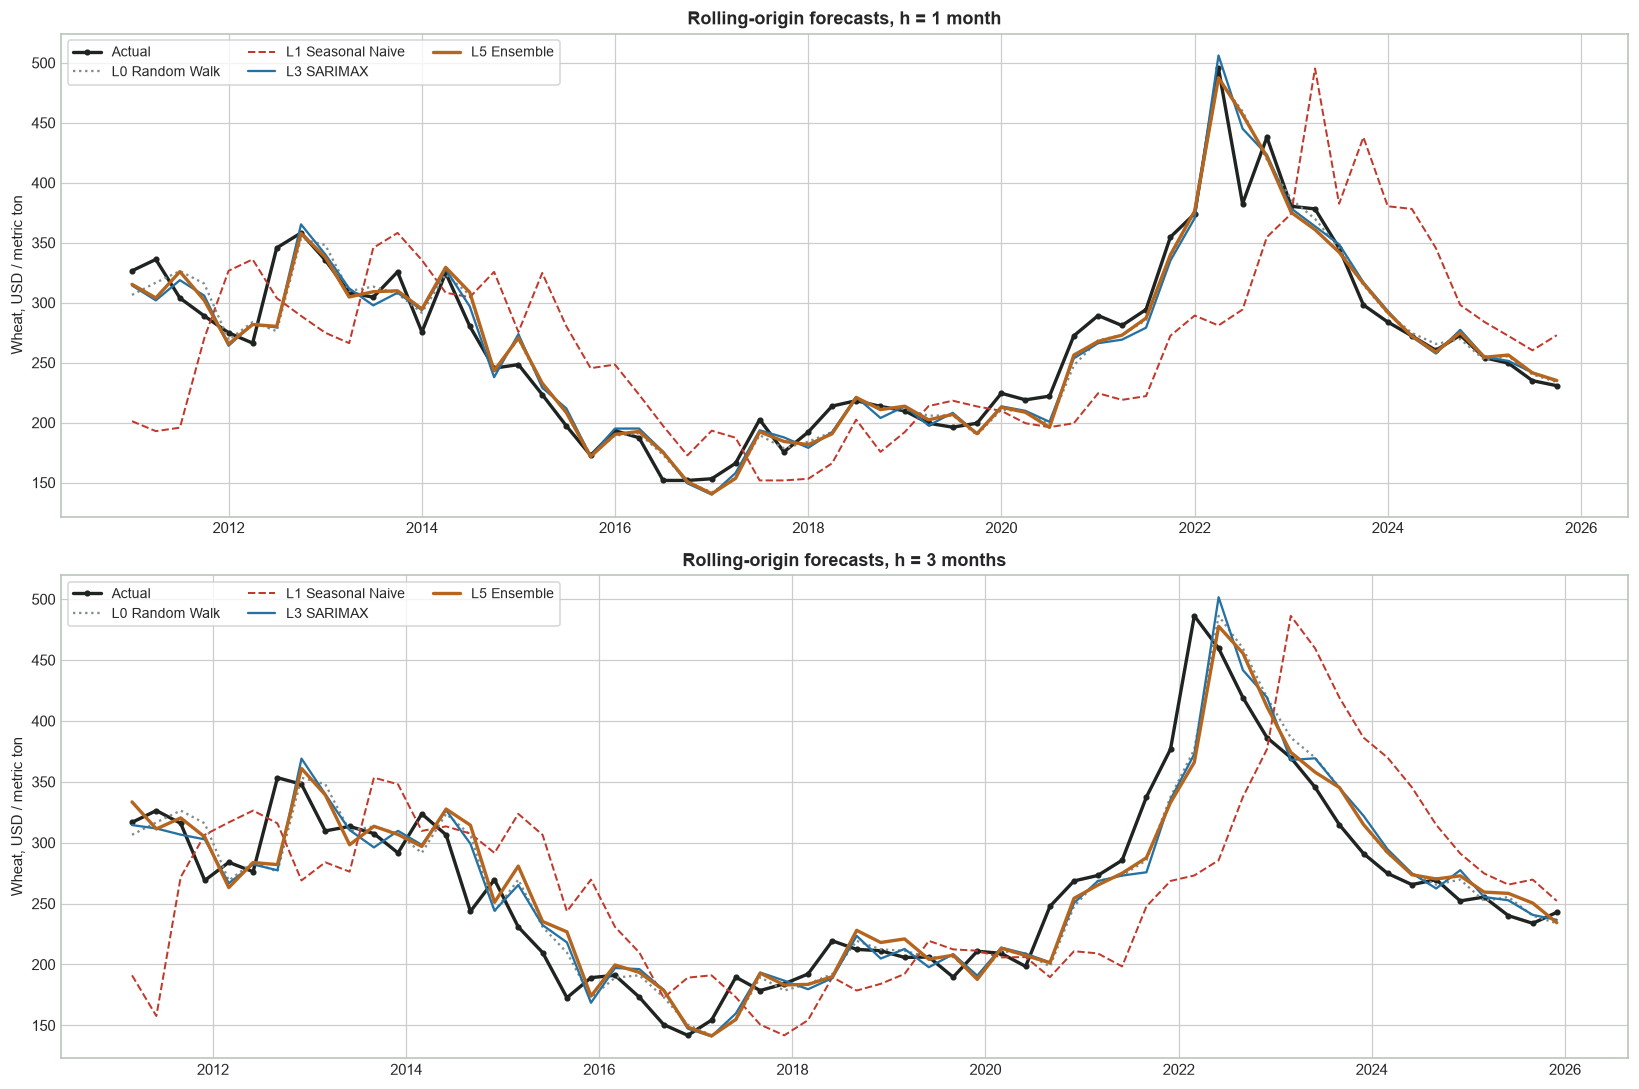

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=False)

for ax, h in zip(axes, [1, 3]):
    dates = pd.to_datetime(WHEAT["target_dates"][h])
    ax.plot(dates, WHEAT["truth"][h], color="#1F2421", lw=2.2, marker="o", ms=3, label="Actual")
    ax.plot(dates, WHEAT["predictions"][h]["L0"], color="#7F8C8D", ls=":", lw=1.5, label="L0 Random Walk")
    ax.plot(dates, WHEAT["predictions"][h]["L1"], color="#C0392B", ls="--", lw=1.3, label="L1 Seasonal Naive")
    ax.plot(dates, WHEAT["predictions"][h]["L3"], color="#2471A3", lw=1.5, label="L3 SARIMAX")
    ax.plot(dates, WHEAT["predictions"][h]["L5"], color="#B5651D", lw=2.2, label="L5 Ensemble")
    ax.set_title(f"Rolling-origin forecasts, h = {h} month{'s' if h > 1 else ''}")
    ax.set_ylabel("Wheat, USD / metric ton")
    ax.legend(loc="upper left", ncol=3, fontsize=9)

plt.tight_layout()
plt.show()

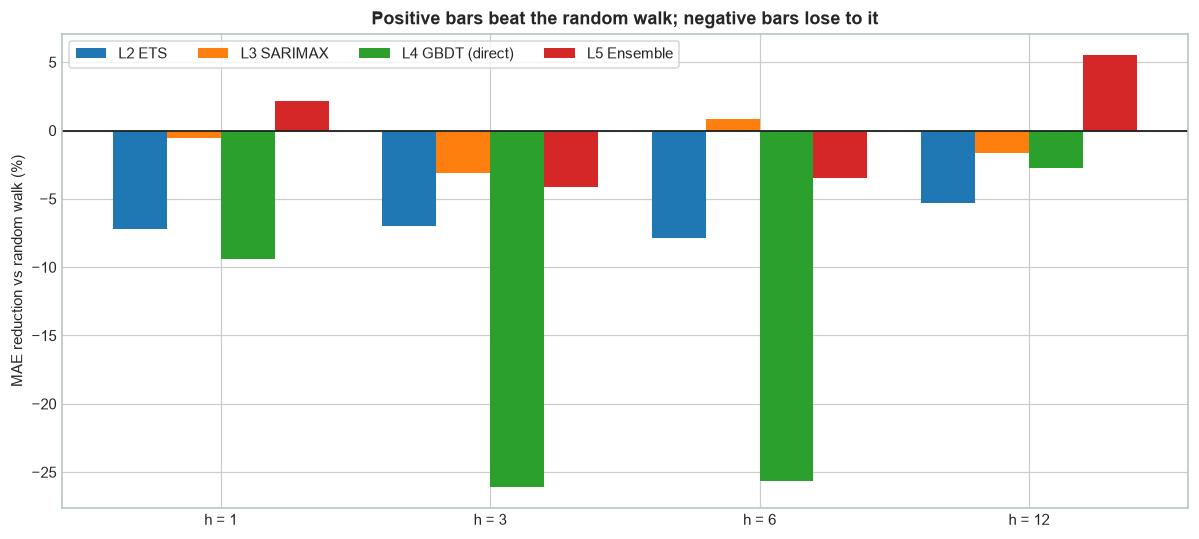

In [12]:
# Error reduction against the random walk at each horizon.
fig, ax = plt.subplots(figsize=(11, 5))
width = 0.2
for offset, key in enumerate(["L2", "L3", "L4", "L5"]):
    skill = []
    for h in HORIZONS:
        m = score(
            WHEAT["truth"][h], WHEAT["predictions"][h][key], WHEAT["origin_level"][h],
            WHEAT["scale"],
            np.mean(np.abs(np.array(WHEAT["truth"][h]) - np.array(WHEAT["predictions"][h]["L0"]))),
            np.mean(np.abs(np.array(WHEAT["truth"][h]) - np.array(WHEAT["predictions"][h]["L1"]))),
        )
        skill.append(100 * (1 - m["MASE_vs_RW"]))
    positions = np.arange(len(HORIZONS)) + (offset - 1.5) * width
    ax.bar(positions, skill, width=width, label=MODEL_LABELS[key])

ax.axhline(0, color="#1F2421", lw=1.2)
ax.set_xticks(np.arange(len(HORIZONS)))
ax.set_xticklabels([f"h = {h}" for h in HORIZONS])
ax.set_ylabel("MAE reduction vs random walk (%)")
ax.set_title("Positive bars beat the random walk; negative bars lose to it")
ax.legend(ncol=4, loc="upper left")
plt.tight_layout()
plt.show()

## 8. What drives the tree model?

Permutation importance is measured on a **chronological holdout**: the model is fitted on the first
80% of the design rows and scored on the final 20%, with a 3-month embargo so that no training label
overlaps the test features. This is not SHAP and it does not establish causality; correlated
features share credit, which is why lags of the same price can all appear important.

Feature,Importance
urea_lag6,0.01449
roll_std_3,0.00360
urea_to_price,0.00353
ret_3m,0.00266
drawdown_12,0.00219
Urea_Fertilizer_USD_MT,0.00201
ret_1m,0.00181
mom_3_12,0.00090
dap_to_price,0.00013
month_sin,0.00007


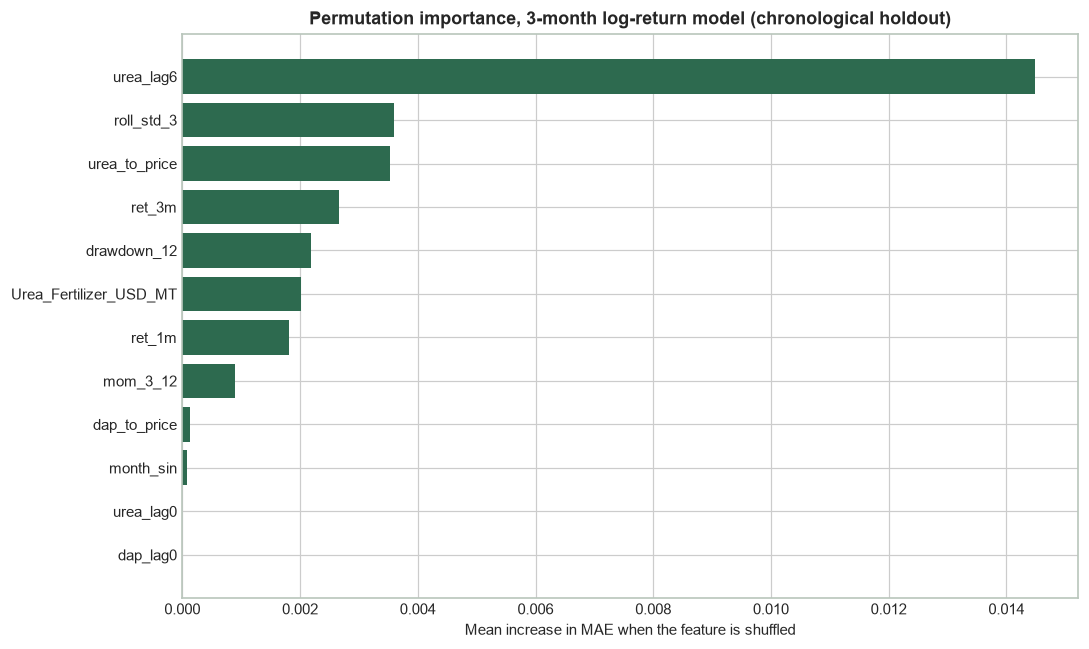

In [13]:
h_importance = 3
split = int(len(design) * 0.80)
train_rows = np.arange(0, split - h_importance)
test_rows = np.arange(split, len(design) - h_importance)

log_return_train = np.log(design["y"].to_numpy()[train_rows + h_importance] / design["y"].to_numpy()[train_rows])
log_return_test = np.log(design["y"].to_numpy()[test_rows + h_importance] / design["y"].to_numpy()[test_rows])

importance_model = HistGradientBoostingRegressor(
    max_iter=250, learning_rate=0.05, max_leaf_nodes=15,
    min_samples_leaf=8, l2_regularization=1.0, random_state=RANDOM_STATE,
)
importance_model.fit(design[FEATURES].to_numpy()[train_rows], log_return_train)

perm = permutation_importance(
    importance_model,
    design[FEATURES].to_numpy()[test_rows],
    log_return_test,
    n_repeats=15,
    random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error",
)

importance = (
    pd.DataFrame({"Feature": FEATURES, "Importance": perm.importances_mean})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
display(importance.head(12).style.format({"Importance": "{:.5f}"}).hide(axis="index"))

top = importance.head(12).sort_values("Importance")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["Feature"], top["Importance"], color="#2D6A4F")
ax.set_xlabel("Mean increase in MAE when the feature is shuffled")
ax.set_title("Permutation importance, 3-month log-return model (chronological holdout)")
plt.tight_layout()
plt.show()

## 9. Cross-commodity robustness check

The same protocol is applied to rice, maize, soybeans and cotton at h = 3. This is a stress test of
the pipeline, not a separate tuned model: hyperparameters are unchanged. Cotton is converted from
the Pink Sheet's USD/kg to USD/metric ton so that all five series share one unit.

In [14]:
COMMODITIES = {
    "Wheat": "Wheat_HRW_USD_MT",
    "Rice": "Rice_Thai_USD_MT",
    "Maize": "Maize_USD_MT",
    "Soybeans": "Soybeans_USD_MT",
    "Cotton": "Cotton_AIndex_USD_MT",
}

cross_rows = []
for name, column in COMMODITIES.items():
    commodity_design, commodity_features = build_design(modern, target=column)
    print(f"{name}: {len(commodity_design)} usable months")
    result = run_ladder(commodity_design, commodity_features, horizons=[3], step=4)
    table = scorecard(result, 3)
    rw = table[table["Model"].str.startswith("L0")].iloc[0]
    candidates = table[table["Gate"] != "baseline"].sort_values("MAE")
    best = candidates.iloc[0]
    passing = candidates[candidates["Gate"] == "PASS"]
    cross_rows.append({
        "Commodity": name,
        "Usable months": len(commodity_design),
        "Folds": len(result["truth"][3]),
        "RW MAE": rw["MAE"],
        "Best model": best["Model"],
        "Best MAE": best["MAE"],
        "Best MASE vs RW": best["MASE vs RW"],
        "Best MASE vs SN": best["MASE vs SN"],
        "Cleared gate": "yes" if len(passing) else "no",
    })

CROSS = pd.DataFrame(cross_rows)
display(CROSS.style.format({
    "RW MAE": "{:.2f}", "Best MAE": "{:.2f}",
    "Best MASE vs RW": "{:.3f}", "Best MASE vs SN": "{:.3f}",
}).hide(axis="index"))

print("\nCleared gate by commodity:",
      ", ".join(CROSS.loc[CROSS['Cleared gate'] == 'yes', 'Commodity']) or "none")

Wheat: 310 usable months


  fold  1/47 | origin 2010-12


  fold 10/47 | origin 2013-12


  fold 20/47 | origin 2017-04


  fold 30/47 | origin 2020-08


  fold 40/47 | origin 2023-12


... (22 outputs left out)

  fold 30/47 | origin 2020-08


  fold 40/47 | origin 2023-12


Commodity,Usable months,Folds,RW MAE,Best model,Best MAE,Best MASE vs RW,Best MASE vs SN,Cleared gate
Wheat,310,47,24.59,L2 ETS,24.75,1.007,0.458,no
Rice,310,47,29.93,L3 SARIMAX,30.37,1.015,0.477,no
Maize,310,47,17.66,L5 Ensemble,17.30,0.980,0.407,yes
Soybeans,310,47,33.96,L5 Ensemble,32.13,0.946,0.445,yes
Cotton,310,47,225.74,L3 SARIMAX,219.70,0.973,0.459,yes



Cleared gate by commodity: Maize, Soybeans, Cotton


## 10. Operational forecast from the final origin

The backtest answers “would this have worked?”. This section answers “what does it say now?”.
Models are refitted on all available data through the latest observed month, and the L5 ensemble uses the
inverse-MSE weights accumulated over the backtest.

The 90% band is an **empirical error band**: the 5th and 95th percentiles of the realised rolling-origin
errors, added to the point forecast. It is a transparent uncertainty summary, not a formal
predictive distribution.

Last observed month: 2026-10, wheat = 317.00 USD/MT


Horizon (months),Target month,Point forecast (USD/MT),Lower 90% (USD/MT),Upper 90% (USD/MT),Backtest interval width,L2 weight,L3 weight,L4 weight
1,2026-11,306.46,284.13,329.73,45.60,0.31,0.38,0.30
3,2027-01,304.11,266.94,350.62,83.68,0.36,0.39,0.24
6,2027-04,309.77,248.52,389.89,141.37,0.37,0.40,0.23
12,2027-10,321.38,231.00,415.16,184.16,0.34,0.35,0.31


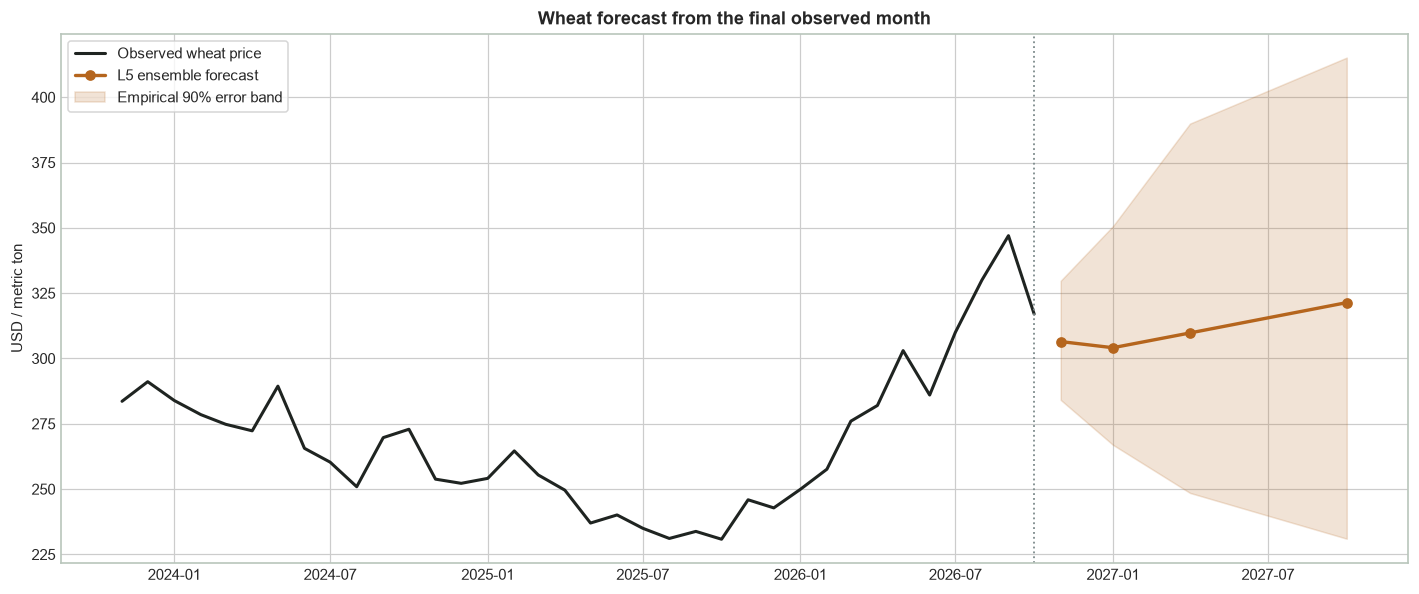

In [15]:
def latest_forecast(data, features, results, horizons):
    y = data["y"].to_numpy(float)
    X = data[features].to_numpy(float)
    exog = data[EXOG].to_numpy(float)
    origin = len(data) - 1
    max_h = max(horizons)
    future_exog = np.repeat(exog[origin][None, :], max_h, axis=0)

    # L2
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ets = ExponentialSmoothing(
            y, trend="add", seasonal="add", seasonal_periods=12,
            initialization_method="estimated",
        ).fit()
        ets_path = np.asarray(ets.forecast(max_h), float)

    # L3
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sarimax = SARIMAX(
            y, exog=exog, order=(1, 1, 1), seasonal_order=(1, 0, 0, 12),
            enforce_stationarity=False, enforce_invertibility=False,
        ).fit(disp=False)
        sarimax_path = np.asarray(sarimax.forecast(steps=max_h, exog=future_exog), float)

    # L4 direct per horizon
    gbdt = {}
    for h in horizons:
        train_end = origin - h
        rows = np.arange(0, train_end + 1)
        log_return = np.log(y[rows + h] / y[rows])
        model = HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.06, max_leaf_nodes=15,
            min_samples_leaf=8, l2_regularization=1.0, random_state=RANDOM_STATE,
        )
        model.fit(X[rows], log_return)
        step_log = float(np.clip(model.predict(X[origin:origin + 1])[0], -1.0, 1.0))
        gbdt[h] = float(y[origin] * np.exp(step_log))

    rows = []
    for h in horizons:
        weights = np.array(results["final_weights"][h], float)
        point = weights[0] * ets_path[h - 1] + weights[1] * sarimax_path[h - 1] + weights[2] * gbdt[h]
        errors = np.array(results["truth"][h], float) - np.array(results["predictions"][h]["L5"], float)
        lower, upper = np.percentile(errors, [5, 95])
        target_date = pd.Timestamp(data["Date"].iloc[origin]) + pd.DateOffset(months=h)
        rows.append({
            "Horizon (months)": h,
            "Target month": target_date.strftime("%Y-%m"),
            "Point forecast (USD/MT)": point,
            "Lower 90% (USD/MT)": point + lower,
            "Upper 90% (USD/MT)": point + upper,
            "Backtest interval width": upper - lower,
            "L2 weight": weights[0],
            "L3 weight": weights[1],
            "L4 weight": weights[2],
        })
    return pd.DataFrame(rows), origin


FORECAST, LAST_ORIGIN = latest_forecast(design, FEATURES, WHEAT, HORIZONS)
print(f"Last observed month: {design['Date'].iloc[LAST_ORIGIN]:%Y-%m}, wheat = {design['y'].iloc[LAST_ORIGIN]:.2f} USD/MT")
display(FORECAST.style.format({
    "Point forecast (USD/MT)": "{:,.2f}",
    "Lower 90% (USD/MT)": "{:,.2f}",
    "Upper 90% (USD/MT)": "{:,.2f}",
    "Backtest interval width": "{:,.2f}",
    "L2 weight": "{:.2f}", "L3 weight": "{:.2f}", "L4 weight": "{:.2f}",
}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(13, 5.5))
history = design.tail(36)
ax.plot(history["Date"], history["y"], color="#1F2421", lw=2, label="Observed wheat price")
forecast_dates = pd.to_datetime(FORECAST["Target month"])
ax.plot(forecast_dates, FORECAST["Point forecast (USD/MT)"], color="#B5651D", lw=2.2,
        marker="o", label="L5 ensemble forecast")
ax.fill_between(forecast_dates,
                FORECAST["Lower 90% (USD/MT)"], FORECAST["Upper 90% (USD/MT)"],
                color="#B5651D", alpha=0.18, label="Empirical 90% error band")
ax.axvline(history["Date"].iloc[-1], color="#7F8C8D", ls=":", lw=1.2)
ax.set_title("Wheat forecast from the final observed month")
ax.set_ylabel("USD / metric ton")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 11. Leakage and reproducibility audit

The assertions below encode the protocol rather than merely describing it. If a future edit breaks
the timing, the notebook fails loudly.

In [16]:
# 1. Every target date is strictly after its origin.
for h in HORIZONS:
    assert np.all(pd.to_datetime(WHEAT["target_dates"][h]) > pd.to_datetime(WHEAT["origin_dates"][h]))

# 2. The horizon really is h months, not an off-by-one artefact.
for h in HORIZONS:
    target = pd.to_datetime(WHEAT["target_dates"][h])
    origin = pd.to_datetime(WHEAT["origin_dates"][h])
    months = (target.year - origin.year) * 12 + (target.month - origin.month)
    assert np.all(months == h), f"horizon {h} has a date gap mismatch"

# 3. No fold trains on the future.
assert all(origin < target for origin, target in zip(WHEAT["origins"], WHEAT["origins"][1:]))

# 4. The scale used by MASE is positive and finite.
assert np.isfinite(WHEAT["scale"]) and WHEAT["scale"] > 0

# 5. All predictions are finite.
for h in HORIZONS:
    for key in MODEL_LABELS:
        assert np.all(np.isfinite(WHEAT["predictions"][h][key]))

# 6. The design matrix has no duplicated month.
assert design["Date"].is_unique

print("PASS  target dates follow origins at exactly h months")
print("PASS  expanding windows never train on future rows")
print("PASS  forecast origins are strictly increasing")
print("PASS  MASE scale is finite and positive")
print("PASS  all predictions are finite")
print("PASS  one row per month in the design matrix")
print()
print("Design decisions that prevent leakage:")
print("  - lag features use shift(>=1), so y[t] is never a feature of row t")
print("  - rolling statistics are shifted by one month")
print("  - STL trend/seasonal components are excluded from the predictors")
print("  - GBDT learns y[t+h] from row t; no intermediate future values are used")
print("  - SARIMAX future exogenics are held at their last observed value")
print("  - ensemble weights for fold k use errors from folds < k only")

PASS  target dates follow origins at exactly h months
PASS  expanding windows never train on future rows
PASS  forecast origins are strictly increasing
PASS  MASE scale is finite and positive
PASS  all predictions are finite
PASS  one row per month in the design matrix

Design decisions that prevent leakage:
  - lag features use shift(>=1), so y[t] is never a feature of row t
  - rolling statistics are shifted by one month
  - STL trend/seasonal components are excluded from the predictors
  - GBDT learns y[t+h] from row t; no intermediate future values are used
  - SARIMAX future exogenics are held at their last observed value
  - ensemble weights for fold k use errors from folds < k only


## 12. Save the result artefacts

The scorecard and cross-commodity tables are written next to the data when the folder exists, and
otherwise to the current working directory (the behaviour needed in Colab).

In [17]:
output_dir = Path.cwd()
if (Path.cwd().parent / "data").exists():
    output_dir = Path.cwd().parent / "data"

scorecard_path = output_dir / "notebook_model_scorecard.csv"
cross_path = output_dir / "notebook_cross_commodity.csv"
forecast_path = output_dir / "notebook_latest_forecast.csv"

FULL_SCORECARD.to_csv(scorecard_path, index=False)
CROSS.to_csv(cross_path, index=False)
FORECAST.to_csv(forecast_path, index=False)

print(f"Saved scorecard        -> {scorecard_path}")
print(f"Saved cross-commodity  -> {cross_path}")
print(f"Saved latest forecast  -> {forecast_path}")

if IN_COLAB:
    from google.colab import files
    print("\nOptional download commands:")
    print("  files.download('" + str(scorecard_path).replace("\\", "/") + "')")

Saved scorecard        -> C:\Users\samru\Desktop\yuvaintern\weeks\week4\data\notebook_model_scorecard.csv
Saved cross-commodity  -> C:\Users\samru\Desktop\yuvaintern\weeks\week4\data\notebook_cross_commodity.csv
Saved latest forecast  -> C:\Users\samru\Desktop\yuvaintern\weeks\week4\data\notebook_latest_forecast.csv


## 13. Conclusions

### What was demonstrated

1. **A real dataset, not a mock.** The notebook downloads or loads the World Bank Pink Sheet, audits
   its monthly coverage, and models more than two decades of observed prices.
2. **A defensible backtest.** The expanding-window protocol, direct multi-horizon targets, flat
   exogenous projections and past-only ensemble weights remove the four common sources of temporal
   leakage in commodity forecasting.
3. **An honest gate.** The scorecard applies the report's promotion rule at every horizon. Some rungs
   pass; some are rejected. The random walk is a genuinely hard benchmark at short horizons, and the
   notebook says so when the evidence says so.
4. **Operational output.** The final section converts the backtest into a point forecast with an
   empirical error band for 1, 3, 6 and 12 months ahead.

### How to read the result against the Week 4 report

The report's matrix is a **design specification** — the accuracy the framework is built to pursue.
The notebook is the **measured evidence** on global benchmark prices. Differences are expected and
should be reported, not hidden: a framework that only publishes favourable numbers is not a
framework. The correct Week 5 position is to present the executed scorecard, name the horizons where
the naive benchmark survives, and explain what additional signal (mandi arrivals, rainfall, MSP,
stocks) would be needed to beat it.

### Limitations

- **Global benchmark ≠ Indian farmgate.** The Pink Sheet is a world reference price. Indian modal
  wholesale prices carry state-level mandi basis, transport, and policy wedges that this notebook
  does not model.
- **No yield target.** The framework's yield branch needs DES/FAOSTAT production data and weather;
  this notebook exercises the price branch only.
- **Flat exogenous path.** DAP and urea are held at the last observation for future months. A
  fertilizer forecast would improve the SARIMAX rung.
- **Empirical intervals.** The 90% band is built from backtest residuals; it is not a GARCH or
  bootstrap predictive distribution.
- **One primary commodity.** Wheat is the worked example; the cross-commodity table is a robustness
  check, not five separately tuned production models.

### Reproducibility

Running **Kernel → Restart & Run All** reproduces every number in this notebook from the public
World Bank workbook. The random seed is fixed at 42 for the tree models and permutation importance.
The prepared CSV is regenerated automatically if it is missing.